# Assignment 10: Adaptive Median Filtering and Otsu Thresholding

**Objective:**
1. Remove salt-and-pepper noise with an adaptive median filter and compare it with a standard median filter using PSNR.
2. Segment an image with Otsu's method, implemented from scratch by maximising the between-class variance.

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Adaptive median filter vs. standard median filter
Salt-and-pepper noise (20 % of pixels) is added first. The adaptive filter starts with a `INITIAL_WINDOW` window and grows it by 2 until it reaches `MAX_WINDOW`.

PSNR of Standard Median: 25.89 dB
PSNR of Adaptive Median: 29.84 dB


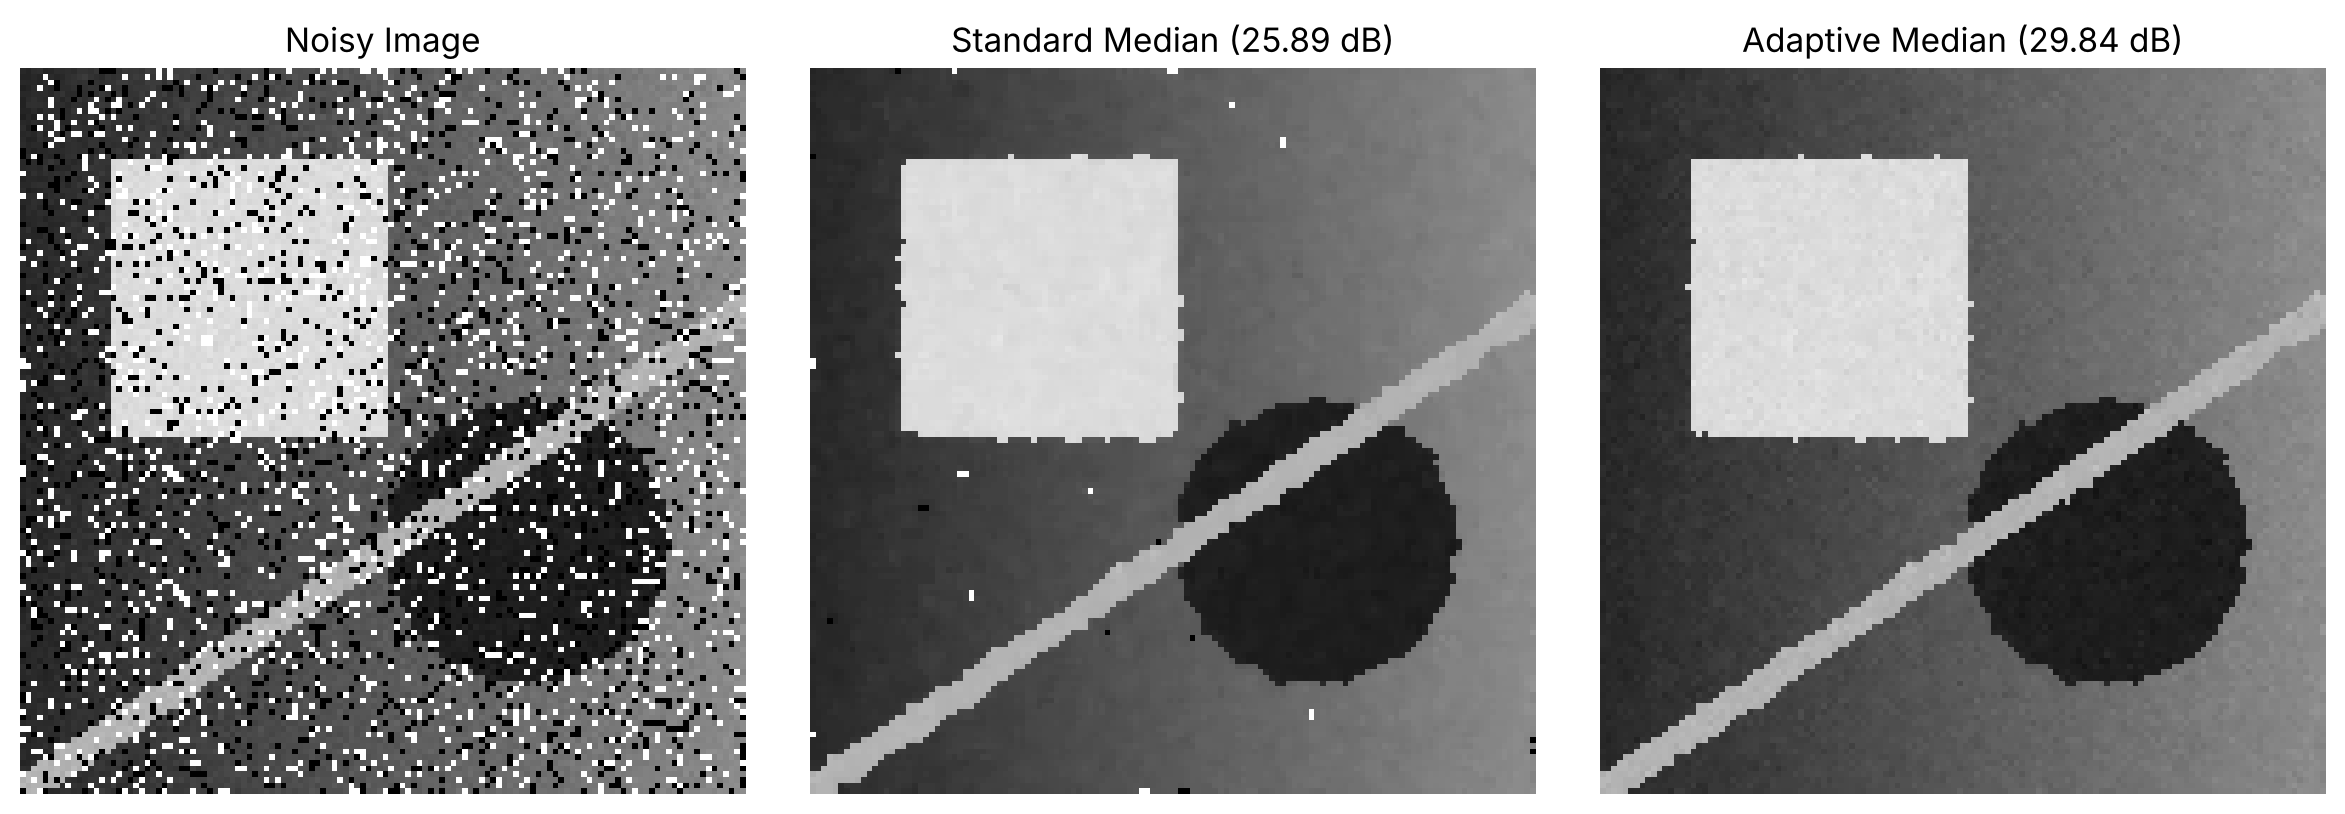

In [2]:
np.random.seed(0)   # reproducible noise

INITIAL_WINDOW = 3   # change me (odd)
MAX_WINDOW = 7       # change me (odd)

grayscale_image = create_demo_image()

# --- Add salt-and-pepper noise ----------------------------------------------
noisy_image = grayscale_image.copy()
noise_probability = 0.2
random_map = np.random.rand(*grayscale_image.shape)
noisy_image[random_map < noise_probability / 2] = 0                                   # pepper
noisy_image[(random_map >= noise_probability / 2) & (random_map < noise_probability)] = 255   # salt

# --- Adaptive median filter ---------------------------------------------------
height, width = grayscale_image.shape
max_pad = MAX_WINDOW // 2
padded_image = cv2.copyMakeBorder(noisy_image, max_pad, max_pad, max_pad, max_pad, cv2.BORDER_REPLICATE)
adaptive_output = np.zeros_like(noisy_image)

for row in range(height):
    for col in range(width):
        padded_row, padded_col = row + max_pad, col + max_pad
        center_value = int(padded_image[padded_row, padded_col])
        window_size = INITIAL_WINDOW

        while window_size <= MAX_WINDOW:
            half = window_size // 2
            window = padded_image[padded_row - half: padded_row + half + 1,
                                  padded_col - half: padded_col + half + 1]
            window_min = int(np.min(window))
            window_max = int(np.max(window))
            window_median = int(np.median(window))

            if window_min < window_median < window_max:
                # Median is not an impulse -> keep pixel if it is not an impulse either
                if window_min < center_value < window_max:
                    adaptive_output[row, col] = center_value
                else:
                    adaptive_output[row, col] = window_median
                break
            else:
                window_size += 2
                if window_size > MAX_WINDOW:
                    adaptive_output[row, col] = window_median
                    break

standard_median_output = cv2.medianBlur(noisy_image, INITIAL_WINDOW)


def compute_psnr(original, filtered):
    """Peak signal-to-noise ratio in dB (higher is better)."""
    mean_squared_error = np.mean((original.astype(float) - filtered.astype(float)) ** 2)
    return 10 * np.log10((255 ** 2) / mean_squared_error) if mean_squared_error > 0 else 100


psnr_standard = compute_psnr(grayscale_image, standard_median_output)
psnr_adaptive = compute_psnr(grayscale_image, adaptive_output)

print(f"PSNR of Standard Median: {psnr_standard:.2f} dB")
print(f"PSNR of Adaptive Median: {psnr_adaptive:.2f} dB")

show_images(
    [noisy_image, standard_median_output, adaptive_output],
    ["Noisy Image", f"Standard Median ({psnr_standard:.2f} dB)", f"Adaptive Median ({psnr_adaptive:.2f} dB)"],
    figsize=(12, 4),
)

## Part B: Otsu's thresholding
For every candidate threshold `t` the between-class variance `w0 * w1 * (mu0 - mu1)^2` is computed; the `t` that maximises it is chosen.

Optimal Otsu Threshold: 145


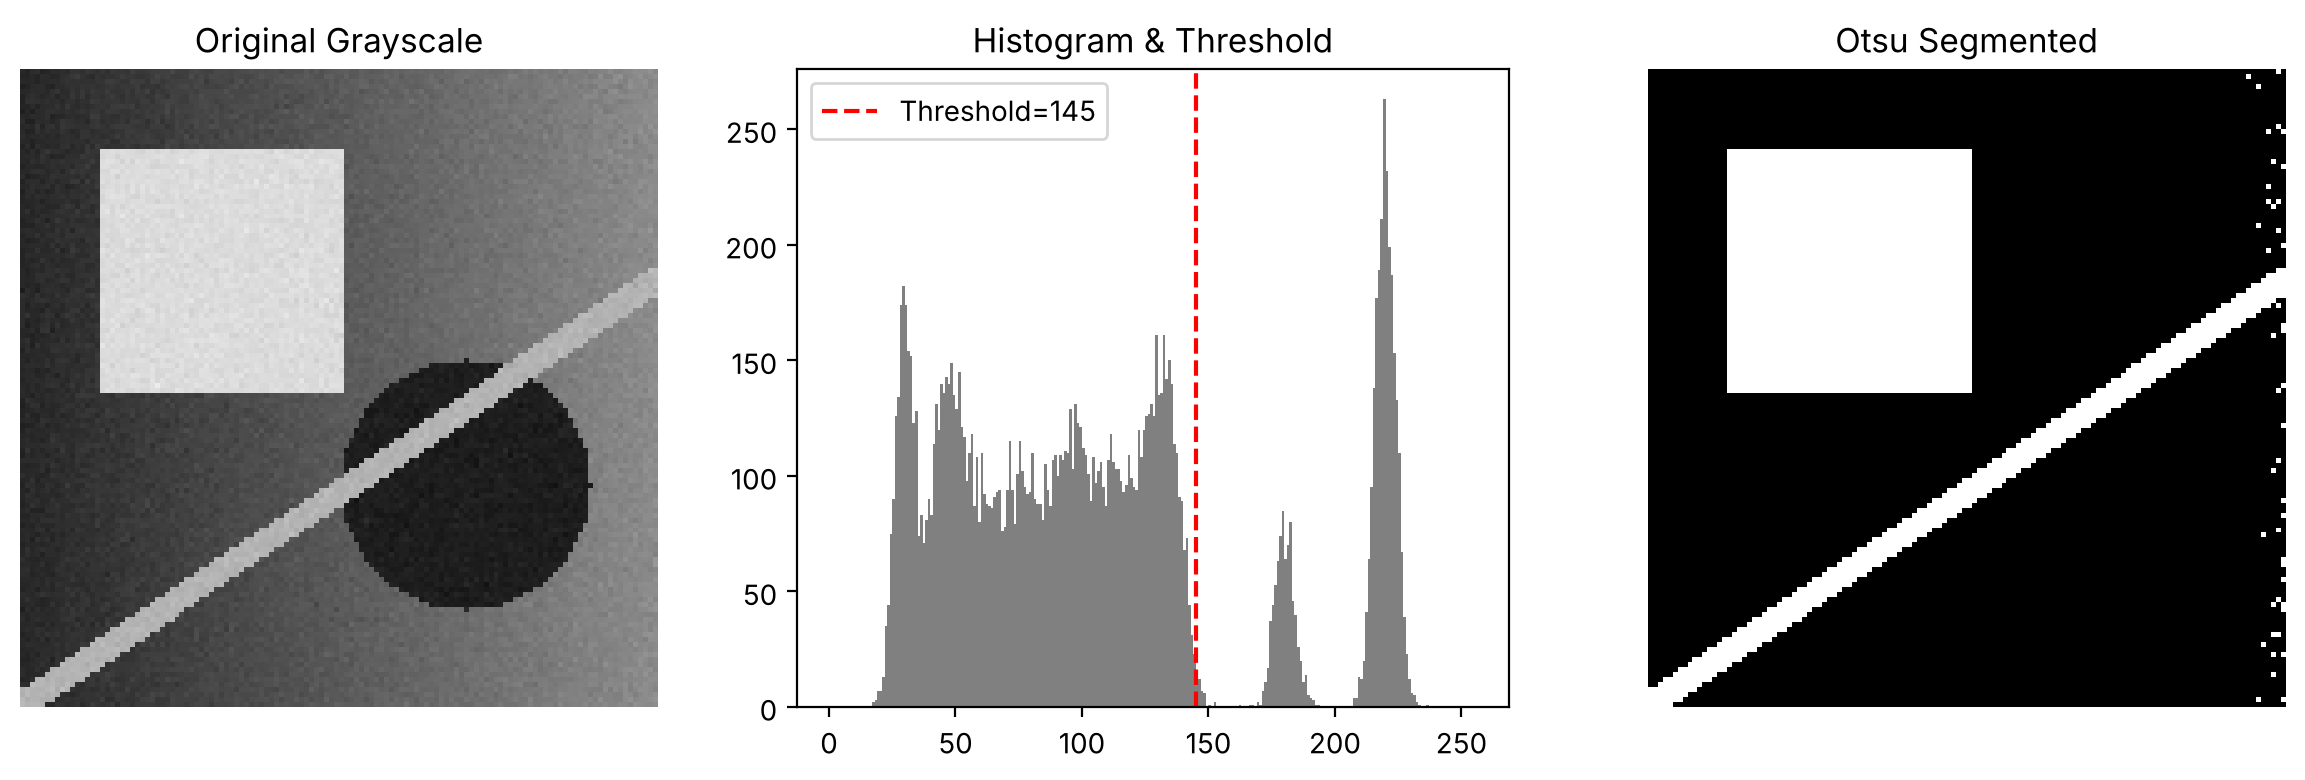

In [3]:
grayscale_image = create_demo_image()

histogram, _ = np.histogram(grayscale_image.flatten(), 256, [0, 256])
probabilities = histogram / grayscale_image.size
intensity_levels = np.arange(256)
total_mean = np.sum(intensity_levels * probabilities)

max_between_variance = -1
best_threshold = 0
class0_weight = 0      # cumulative probability of class 0 (pixels <= t)
class0_mean_sum = 0    # cumulative sum of i * p(i) up to t

for threshold in range(256):
    class0_weight += probabilities[threshold]
    class0_mean_sum += threshold * probabilities[threshold]
    class1_weight = 1 - class0_weight

    if class0_weight == 0 or class1_weight == 0:
        continue

    class0_mean = class0_mean_sum / class0_weight
    class1_mean = (total_mean - class0_mean_sum) / class1_weight
    between_class_variance = class0_weight * class1_weight * ((class0_mean - class1_mean) ** 2)

    if between_class_variance > max_between_variance:
        max_between_variance = between_class_variance
        best_threshold = threshold

segmented_image = np.where(grayscale_image >= best_threshold, 255, 0).astype(np.uint8)

print("Optimal Otsu Threshold:", best_threshold)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(grayscale_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.hist(grayscale_image.ravel(), bins=256, range=(0, 256), color="gray")
plt.axvline(best_threshold, color="red", linestyle="dashed", label=f"Threshold={best_threshold}")
plt.title("Histogram & Threshold")
plt.legend()

plt.subplot(1, 3, 3)
plt.imshow(segmented_image, cmap="gray", vmin=0, vmax=255)
plt.title("Otsu Segmented")
plt.axis("off")

plt.tight_layout()
plt.show()